# Pembersihan Data

#Bagian 1
1. mengimport dataset dari google drive
2. membuat folder engine dan file schema.py didalamnya
3. membuat file __init__.py dan data.py dalam folder engine
4. melakukan uji import paket engine

In [56]:
import os
import shutil
import json
import numpy as np
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')
folder_drive = '/content/drive/MyDrive/Praktikum MLN/Dataset ML'
print(os.path.exists(folder_drive))      # harus True
print(sorted(os.listdir(folder_drive)))

os.makedirs('/content/data/raw', exist_ok=True)     # file NASA asli
os.makedirs('/content/data/hasil', exist_ok=True)   # JSON untuk web
os.makedirs('/content/models/v1', exist_ok=True)    # artefak model
os.makedirs('/content/engine', exist_ok=True)       # kode Python bersama

print(sorted(os.listdir('/content')))

for nama in ['train_FD002.txt', 'train_FD004.txt']:
    shutil.copy(f'{folder_drive}/{nama}', f'/content/data/raw/{nama}')

print(os.listdir('/content/data/raw'))

with open('/content/data/raw/train_FD002.txt') as f:
    for i in range(2):
        print(repr(f.readline()))

isi_schema = r'''# Skema data C-MAPSS, dipakai semua modul (Kontrak 1 dan 2)
KOLOM_ALL = ['unit_asli', 'cycle', 'set1', 'set2', 'set3'] + [f's{i}' for i in range(1, 22)]
SENSOR_ALL = [f's{i}' for i in range(1, 22)]
SENSOR_AKTIF = ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
SENSOR_DIBUANG = ['s1', 's5', 's6', 's10', 's16', 's18', 's19']
SETTING = ['set1', 'set2', 'set3']
'''

with open('/content/engine/schema.py', 'w') as f:
    f.write(isi_schema)

print("schema.py dibuat")

isi_data = r'''import json
import pandas as pd
from .schema import KOLOM_ALL

def load_and_format(filepath, prefix):
    df = pd.read_csv(filepath, sep=r'\s+', header=None, names=KOLOM_ALL)
    df['unit'] = prefix + "_" + df['unit_asli'].astype(str)
    df = df.drop(columns=['unit_asli'])
    return df

def load_splits(filepath='data/splits.json'):
    with open(filepath, 'r') as f:
        return json.load(f)
'''

with open('/content/engine/data.py', 'w') as f:
    f.write(isi_data)

open('/content/engine/__init__.py', 'a').close()

print(sorted(os.listdir('/content/engine')))   # ['__init__.py', 'data.py', 'schema.py'] (+ file lain kalau ada)

import sys
sys.path.insert(0, '/content')

from engine import schema, data

print(len(schema.KOLOM_ALL), len(schema.SENSOR_AKTIF), len(schema.SENSOR_DIBUANG))   # 26 14 7

df_uji = data.load_and_format('/content/data/raw/train_FD002.txt', 'FD002')
print(df_uji.shape)                        # (53759, 26)
print(df_uji[['unit', 'cycle']].head(3))   # FD002_1 dengan cycle 1, 2, 3

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
True
['RUL_FD001.txt', 'RUL_FD002.txt', 'RUL_FD003.txt', 'RUL_FD004.txt', 'ai4i2020.csv', 'animal_data_dirty1_v2.csv', 'manufacturing_defect_dataset.csv', 'semiconductor_wafer_defect_dataset.csv', 'test_FD001.txt', 'test_FD002.txt', 'test_FD003.txt', 'test_FD004.txt', 'train_FD001.txt', 'train_FD002.txt', 'train_FD003.txt', 'train_FD004.txt']
['.config', 'data', 'drive', 'engine', 'models', 'sample_data']
['train_FD004.txt', 'train_FD002.txt']
'1 1 34.9983 0.8400 100.0 449.44 555.32 1358.61 1137.23 5.48 8.00 194.64 2222.65 8341.91 1.02 42.02 183.06 2387.72 8048.56 9.3461 0.02 334 2223 100.00 14.73 8.8071  \n'
'1 2 41.9982 0.8408 100.0 445.00 549.90 1353.22 1125.78 3.91 5.71 138.51 2211.57 8303.96 1.02 42.20 130.42 2387.66 8072.30 9.3774 0.02 330 2212 100.00 10.41 6.2665  \n'
schema.py dibuat
['__init__.py', '__pycache__', 'conditions.py', 'data.py', 'health.p

kolom unit_asli dari file NASA diganti menjadi unit dengan awalan subset (FD002_1, FD004_1), supaya nomor mesin yang sama di dua subset tidak bentrok. Daftar sensor disimpan di schema.py supaya semua anggota tim memakai daftar yang sama.

In [57]:
import sys
sys.path.insert(0, '/content')

import pandas as pd
import numpy as np
from engine import schema, data

df_002 = data.load_and_format('/content/data/raw/train_FD002.txt', 'FD002')
df_004 = data.load_and_format('/content/data/raw/train_FD004.txt', 'FD004')
df_all = pd.concat([df_002, df_004], ignore_index=True)

print("FD002:", df_002.shape)
print("FD004:", df_004.shape)
print("Gabungan:", df_all.shape)

FD002: (53759, 26)
FD004: (61249, 26)
Gabungan: (115008, 26)


pd.concat(..., ignore_index=True) menempel dua tabel ke bawah dan mengulang nomor baris dari 0.

Baris FD002 + FD004 = 115.008, cocok dengan angka “115 ribu” di dokumen kontrak.



In [58]:
subset = df_all['unit'].str[:5]
print(df_all.groupby(subset)['unit'].nunique())
print("Total mesin:", df_all['unit'].nunique())

unit
FD002    260
FD004    249
Name: unit, dtype: int64
Total mesin: 509


str[:5] mengambil lima huruf pertama ID (FD002 atau FD004) untuk mengelompokkan. Total 509 mesin sama dengan angka di diagram alur sistem dokumen tim.



In [59]:
print(df_all.dtypes.value_counts())
print()
print(df_all[['unit', 'cycle', 'set1', 's17', 's18']].dtypes)

float64    22
int64       3
object      1
Name: count, dtype: int64

unit      object
cycle      int64
set1     float64
s17        int64
s18        int64
dtype: object


semua kolom numerik sudah berupa angka, jadi tidak ada kolom yang terbaca sebagai teks karena salah format. Ini bukti awal bahwa data tidak bermasalah tipe

In [60]:
df_all.head(3)

,cycle,set1,set2,set3,s1,s2,s3,s4,s5,s6,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,unit
0,1,34.9983,0.8400,100.0,449.44,555.32,1358.61,1137.23,5.48,8.00,...,2387.72,8048.56,9.3461,0.02,334,2223,100.00,14.73,8.8071,FD002_1
1,2,41.9982,0.8408,100.0,445.00,549.90,1353.22,1125.78,3.91,5.71,...,2387.66,8072.30,9.3774,0.02,330,2212,100.00,10.41,6.2665,FD002_1
2,3,24.9988,0.6218,60.0,462.54,537.31,1256.76,1047.45,7.05,9.02,...,2028.03,7864.87,10.8941,0.02,309,1915,84.93,14.08,8.6723,FD002_1


# Bagian 3
memeriksa missing value dan file duplikat


In [61]:
for nama in ['train_FD002.txt', 'train_FD004.txt']:
    raw = pd.read_csv(f'/content/data/raw/{nama}', sep=r'\s+', header=None)
    print(nama, "->", raw.shape[1], "kolom")

print("Total missing:", df_all.isnull().sum().sum())
print("Kolom yang punya missing:", df_all.columns[df_all.isnull().any()].tolist())

print("Baris duplikat penuh:", df_all.duplicated().sum())
print("Duplikat kunci (unit, cycle):", df_all.duplicated(subset=['unit', 'cycle']).sum())

kolom_angka = df_all.drop(columns='unit')
print("Nilai inf:", np.isinf(kolom_angka).sum().sum())

train_FD002.txt -> 26 kolom
train_FD004.txt -> 26 kolom
Total missing: 0
Kolom yang punya missing: []
Baris duplikat penuh: 0
Duplikat kunci (unit, cycle): 0
Nilai inf: 0


file NASA punya spasi di akhir tiap baris. Di beberapa kasus itu membuat pandas membaca kolom ke-27 yang kosong. Angka 26 membuktikan hal itu tidak terjadi, jadi pemberian nama kolom kita (names=KOLOM_ALL) tidak bergeser.

isnull() menandai sel kosong, .sum() menjumlahkannya per kolom, lalu .sum() kedua menjumlahkan seluruh kolom. Baris kedua menyebutkan kolom mana yang bermasalah (kosong kalau tidak ada).

ada dua jenis duplikat.

Duplikat penuh: seluruh 26 kolom sama persis di dua baris.
Duplikat kunci: satu mesin punya dua baris untuk siklus yang sama, yang tidak boleh terjadi karena cycle harus unik per mesin.

dan dataset ini tidak memiliki kedua jenis data duplikat tersebut

nilai inf tidak terdeteksi oleh isnull(), tapi bisa merusak perhitungan rata-rata dan K-Means. Kolom unit dikeluarkan karena berisi teks.

# bagian 4


In [62]:
g = df_all[df_all['unit'] == 'FD002_1']['cycle'].values
print("Siklus pertama:", g[0])
print("Siklus terakhir:", g[-1])
print("Jumlah baris:", len(g))
print("Selisih antar baris (unik):", np.unique(np.diff(g)))

bermasalah = []

for u, g in df_all.groupby('unit'):
    c = g['cycle'].values
    mulai_dari_1 = (c[0] == 1)
    naik_satu = (np.diff(c) == 1).all()
    if not (mulai_dari_1 and naik_satu):
        bermasalah.append(u)

print("Jumlah mesin dicek:", df_all['unit'].nunique())
print("Mesin dengan siklus bermasalah:", len(bermasalah))
print(bermasalah[:10])

urut = df_all.sort_values(['unit', 'cycle']).index
print("Baris sudah terurut per unit dan cycle?", (df_all.index == urut).all())

print("Setiap mesin berurutan di file:", df_all.groupby('unit')['cycle'].apply(lambda s: s.is_monotonic_increasing).all())

Siklus pertama: 1
Siklus terakhir: 149
Jumlah baris: 149
Selisih antar baris (unik): [1]
Jumlah mesin dicek: 509
Mesin dengan siklus bermasalah: 0
[]
Baris sudah terurut per unit dan cycle? False
Setiap mesin berurutan di file: True


np.diff menghitung selisih tiap baris dengan baris sebelumnya. Kalau semua selisihnya 1, tidak ada siklus yang terlewat. Kalau siklus terakhir sama dengan jumlah baris, berarti tidak ada baris yang hilang di tengah.

groupby('unit') memecah data per mesin. Untuk tiap mesin kita cek dua syarat: mulai dari 1 dan naik 1 terus. Mesin yang gagal salah satunya dimasukkan ke daftar bermasalah.



# Bagian 5

(509, 3)
        unit  umur subset
0    FD002_1   149  FD002
1   FD002_10   184  FD002
2  FD002_100   212  FD002
Total siklus: 115008
        count   mean   std    min    25%    50%    75%    max
subset                                                       
FD002   260.0  206.8  46.8  128.0  174.0  199.0  230.2  378.0
FD004   249.0  246.0  73.1  128.0  190.0  234.0  290.0  543.0


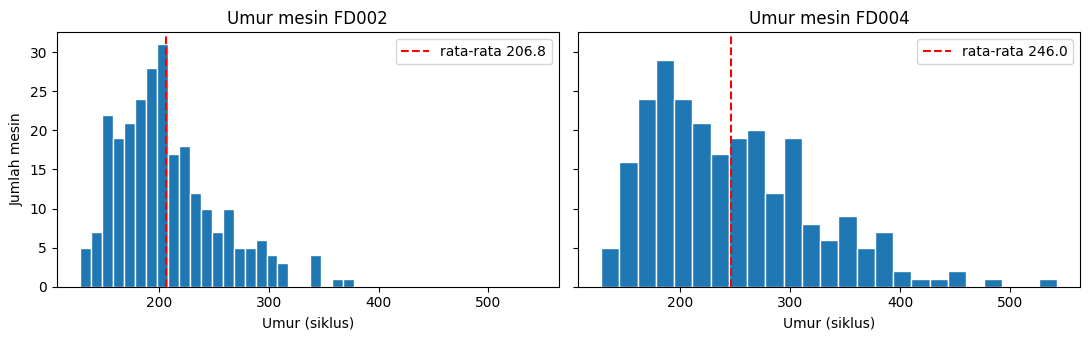

Batas atas IQR: 383.5
Jumlah mesin di atas batas: 10
        count  max
subset            
FD004      10  543


In [63]:
umur = df_all.groupby('unit')['cycle'].max().rename('umur').reset_index()
umur['subset'] = umur['unit'].str[:5]

print(umur.shape)          # (509, 3)
print(umur.head(3))
print("Total siklus:", umur['umur'].sum())   # 115008

print(umur.groupby('subset')['umur'].describe().round(1))

import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharex=True, sharey=True)
for a, nama in zip(ax, ['FD002', 'FD004']):
    d = umur[umur['subset'] == nama]['umur']
    a.hist(d, bins=25, edgecolor='white')
    a.axvline(d.mean(), color='red', linestyle='--', label=f'rata-rata {d.mean():.1f}')
    a.set_title(f'Umur mesin {nama}')
    a.set_xlabel('Umur (siklus)')
    a.legend()
ax[0].set_ylabel('Jumlah mesin')
plt.tight_layout()
plt.show()

q1, q3 = umur['umur'].quantile([0.25, 0.75])
batas_atas = q3 + 1.5 * (q3 - q1)
ekstrem = umur[umur['umur'] > batas_atas]
print("Batas atas IQR:", round(batas_atas, 1))
print("Jumlah mesin di atas batas:", len(ekstrem))
print(ekstrem.groupby('subset')['umur'].agg(['count', 'max']))

umur mesin sangat bervariasi, dan FD004 lebih tidak teratur karena punya dua mode kerusakan. Mesin berumur panjang tidak dibuang, karena itu kejadian nyata, bukan kesalahan data. Inilah juga alasan kita menganalisis tahap kesehatan menurut persentase umur, bukan nomor siklus: 100 siklus berarti “tengah umur” untuk satu mesin tetapi “hampir rusak” untuk mesin lain.
karena cycle mulai dari 1 dan naik 1 (terbukti di Langkah 4), siklus maksimum sebuah mesin sama dengan umurnya. Total umur semua mesin harus sama dengan jumlah baris. Kalau cocok, berarti tidak ada baris yang hilang.

count adalah jumlah mesin, mean rata-rata umur, std sebaran umur.
Umur terpendek di kedua subset adalah 128 siklus, jauh di atas batas minimal 10 siklus di Kontrak 2.
FD004 rata-ratanya lebih panjang dan sebarannya lebih lebar. Itu masuk akal karena FD004 punya dua mode kerusakan sekaligus.

sharex=True dan sharey=True membuat kedua grafik memakai skala sama, jadi perbandingannya jujur.
Histogram FD004 akan tampak lebih melebar ke kanan (ekor panjang sampai 543), sedangkan FD002 lebih ramping.
Garis merah putus-putus menandai rata-rata.

aturan IQR menandai mesin yang umurnya jauh di atas kebanyakan mesin lain. Mesin ini tidak kita buang, karena umur panjang adalah kejadian nyata, bukan kesalahan data. Kita hanya mencatat jumlahnya sebagai bagian dari temuan EDA. Kalau ada, hampir semuanya berasal dari FD004.

# Pembagian/split data

#Bagian 1 - Ambil Daftar ID mesin tiap subset


In [64]:
def get_unit_ids(filepath, prefix):
    df = pd.read_csv(filepath, sep=r'\s+', header=None)
    return [f"{prefix}_{int(u)}" for u in df[0].unique()]

units_fd002 = get_unit_ids('/content/data/raw/train_FD002.txt', 'FD002')
units_fd004 = get_unit_ids('/content/data/raw/train_FD004.txt', 'FD004')

print(len(units_fd002), len(units_fd004))   # 260 249
print(units_fd002[:3])                       # ['FD002_1', 'FD002_2', 'FD002_3']



260 249
['FD002_1', 'FD002_2', 'FD002_3']


Bagian 2- acak dan bagi per subset

In [65]:
def split_60_20_20(unit_list, seed=42):
    np.random.seed(seed)
    shuffled = np.random.permutation(unit_list)
    n = len(shuffled)
    idx_a = int(0.6 * n)
    idx_b = int(0.8 * n)
    return {
        'A': shuffled[:idx_a].tolist(),
        'B': shuffled[idx_a:idx_b].tolist(),
        'C': shuffled[idx_b:].tolist(),
    }

split_002 = split_60_20_20(units_fd002, seed=42)
split_004 = split_60_20_20(units_fd004, seed=42)

for nama, s in [('FD002', split_002), ('FD004', split_004)]:
    print(nama, "-> A:", len(s['A']), "B:", len(s['B']), "C:", len(s['C']))

FD002 -> A: 156 B: 52 C: 52
FD004 -> A: 149 B: 50 C: 50


Bagian 3- Gabungkan dan simpan

In [66]:
splits = {
    "seed": 42,
    "A": split_002['A'] + split_004['A'],
    "B": split_002['B'] + split_004['B'],
    "C": split_002['C'] + split_004['C'],
}

with open('/content/data/splits.json', 'w') as f:
    json.dump(splits, f)

print("Jumlah -> A:", len(splits['A']), "| B:", len(splits['B']), "| C:", len(splits['C']))
print("Contoh A:", splits['A'][:3])
print("Contoh B:", splits['B'][:3])
print("Contoh C:", splits['C'][:3])

Jumlah -> A: 305 | B: 102 | C: 102
Contoh A: ['FD002_31', 'FD002_182', 'FD002_224']
Contoh B: ['FD002_71', 'FD002_250', 'FD002_65']
Contoh C: ['FD002_135', 'FD002_252', 'FD002_244']


Bagian 4- Verifikasi

In [67]:
splits = json.load(open('/content/data/splits.json'))
A, B, C = set(splits['A']), set(splits['B']), set(splits['C'])
semua_mesin = set(df_all['unit'].unique())

print("A&B:", len(A & B), "| A&C:", len(A & C), "| B&C:", len(B & C))   # 0 0 0
print("Gabungan = 509 mesin data?", (A | B | C) == semua_mesin)         # True

umur = df_all.groupby('unit')['cycle'].max().rename('umur').reset_index()
umur['subset'] = umur['unit'].str[:5]
umur['kelompok'] = umur['unit'].map(lambda u: 'A' if u in A else ('B' if u in B else 'C'))

print(pd.crosstab(umur['subset'], umur['kelompok']))
print(umur.groupby('kelompok')['umur'].agg(['count', 'mean', 'min', 'max']).round(1))

os.makedirs('/content/drive/MyDrive/Praktikum MLN/PrognoSense', exist_ok=True)
shutil.copy('/content/data/splits.json', '/content/drive/MyDrive/Praktikum MLN/PrognoSense/splits.json')
print("Tersimpan di Drive")

A&B: 0 | A&C: 0 | B&C: 0
Gabungan = 509 mesin data? True
kelompok    A   B   C
subset               
FD002     156  52  52
FD004     149  50  50
          count   mean  min  max
kelompok                        
A           305  223.9  128  543
B           102  226.4  144  399
C           102  231.6  128  446
Tersimpan di Drive


# Mengelompokan Data

In [68]:
import matplotlib.pyplot as plt
import joblib
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df_A = df_all[df_all['unit'].isin(splits['A'])].copy()
X_cond = df_A[['set1', 'set2', 'set3']]

print("Baris A:", df_A.shape)                 # (68291, 26)
print("Mesin A:", df_A['unit'].nunique())     # 305
print(X_cond.describe().round(3))


Baris A: (68291, 26)
Mesin A: 305
            set1       set2       set3
count  68291.000  68291.000  68291.000
mean      23.990      0.572     94.019
std       14.750      0.310     14.265
min        0.000      0.000     60.000
25%       10.005      0.251    100.000
50%       25.001      0.700    100.000
75%       41.998      0.840    100.000
max       42.008      0.842    100.000


    K         WCSS  Silhouette
0   2  1089229.873       0.648
1   3   174909.435       0.802
2   4    60931.386       0.813
3   5    21794.361       0.930
4   6        0.039       1.000
5   7        0.031       0.897
6   8        0.026       0.831
7   9        0.021       0.771
8  10        0.017       0.703


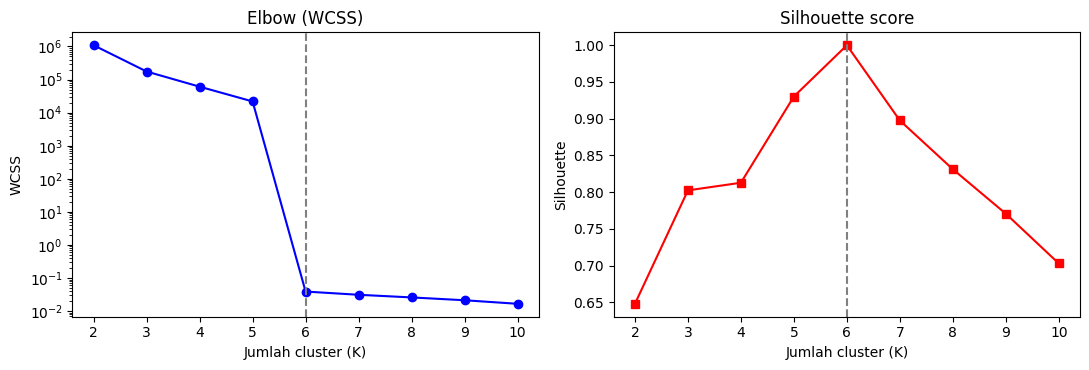

In [69]:
X_sample = X_cond.sample(n=5000, random_state=42)   # subset supaya silhouette cepat

k_range = range(2, 11)
wcss, silhouettes = [], []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_sample)
    wcss.append(km.inertia_)
    silhouettes.append(silhouette_score(X_sample, labels))

hasil_k = pd.DataFrame({'K': list(k_range), 'WCSS': wcss, 'Silhouette': silhouettes})
print(hasil_k.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))

ax[0].plot(list(k_range), wcss, 'bo-')
ax[0].axvline(6, color='gray', linestyle='--')
ax[0].set_title('Elbow (WCSS)')
ax[0].set_xlabel('Jumlah cluster (K)')
ax[0].set_ylabel('WCSS')
ax[0].set_yscale('log')   # skala log karena WCSS turun dari jutaan ke hampir 0

ax[1].plot(list(k_range), silhouettes, 'rs-')
ax[1].axvline(6, color='gray', linestyle='--')
ax[1].set_title('Silhouette score')
ax[1].set_xlabel('Jumlah cluster (K)')
ax[1].set_ylabel('Silhouette')

plt.tight_layout()
plt.show()

In [70]:
kmeans_final = KMeans(n_clusters=6, n_init=10, random_state=42)
df_A['kondisi'] = kmeans_final.fit_predict(X_cond)

print(df_A['kondisi'].value_counts().sort_index())

centroid = pd.DataFrame(np.round(kmeans_final.cluster_centers_, 3),
                        columns=['set1', 'set2', 'set3'])
print(centroid.sort_values('set1').reset_index(drop=True))

jarak = np.linalg.norm(X_cond.values - kmeans_final.cluster_centers_[df_A['kondisi']], axis=1)
print("Jarak terjauh titik ke centroidnya:", jarak.max())

idx = X_cond.sample(n=5000, random_state=42).index
sil_kondisi = float(silhouette_score(X_cond.loc[idx], df_A.loc[idx, 'kondisi']))
print("Silhouette K=6:", round(sil_kondisi, 4))     # sekitar 0.9997

joblib.dump(kmeans_final, '/content/models/v1/kmeans_cond.joblib')
print(os.listdir('/content/models/v1'))              # ['kmeans_cond.joblib']

kondisi
0    10211
1    17083
2    10212
3    10360
4    10210
5    10215
Name: count, dtype: int64
     set1   set2   set3
0   0.002  0.000  100.0
1  10.003  0.250  100.0
2  20.003  0.701  100.0
3  25.003  0.621   60.0
4  35.003  0.841  100.0
5  42.003  0.840  100.0
Jarak terjauh titik ke centroidnya: 0.005269505005376995
Silhouette K=6: 0.9997
['kmeans_cond.joblib', 'norm_stats.json', 'health_kmeans.joblib']


# Pemilihan Sensor

kondisi        0        1        2        3        4        5
s1        0.0000   0.0000   0.0000   0.0000   0.0000   0.0000
s2        0.5165   0.4672   0.3818   0.5107   0.5026   0.4815
s3        6.4593   6.2814   5.6679   6.3272   6.3473   6.1752
s4        9.5350   8.6194   7.4124   9.2321   8.6131   8.3018
s5        0.0000   0.0000   0.0000   0.0000   0.0000   0.0000
s6        0.0125   0.0096   0.0108   0.0128   0.0197   0.0110
s7        2.6947   0.8190   0.8373   1.8608   1.5908   1.0710
s8        0.1204   0.2704   0.2313   0.1483   0.1694   0.2659
s9       18.7499  18.2550  13.4309  18.4029  17.2130  17.3706
s10       0.0026   0.0052   0.0015   0.0023   0.0051   0.0053
s11       0.2862   0.2743   0.2356   0.2831   0.2695   0.2634
s12       2.5331   0.7401   0.7519   1.7318   1.4838   0.9845
s13       0.1205   0.2917   0.2448   0.1523   0.1749   0.2855
s14      16.0141  16.6309  12.1512  15.9301  14.9516  15.6961
s15       0.0551   0.0621   0.0654   0.0563   0.0575   0.0610
s16     

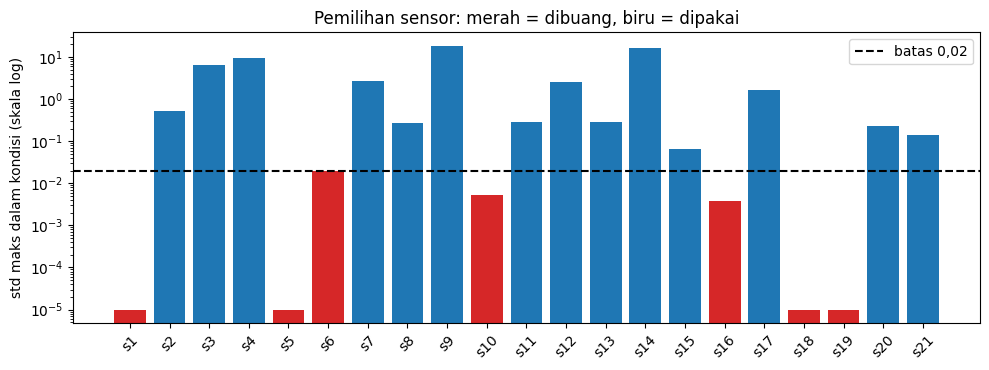

In [71]:
sensor_all = schema.SENSOR_ALL

std_per_kondisi = df_A.groupby('kondisi')[sensor_all].std()
print(std_per_kondisi.round(4).T)      # baris = sensor, kolom = kondisi 0..5
std_maks = std_per_kondisi.max().rename('std_maks_dalam_kondisi')
tabel = std_maks.to_frame()
tabel['dipakai'] = tabel['std_maks_dalam_kondisi'] > 0.02

print(tabel.round(4))
print()
print("Dipakai :", tabel.index[tabel['dipakai']].tolist())
print("Dibuang :", tabel.index[~tabel['dipakai']].tolist())

dibuang_data = set(tabel.index[~tabel['dipakai']])
aktif_data = set(tabel.index[tabel['dipakai']])

print("Dibuang cocok dengan schema.SENSOR_DIBUANG?", dibuang_data == set(schema.SENSOR_DIBUANG))
print("Aktif cocok dengan schema.SENSOR_AKTIF?   ", aktif_data == set(schema.SENSOR_AKTIF))

std_global = df_A[sensor_all].std().rename('std_global')
bandingan = pd.concat([std_global, std_maks], axis=1).round(4)
print(bandingan.loc[['s1', 's5', 's6', 's10', 's16', 's18', 's19']])

fig, ax = plt.subplots(figsize=(10, 3.8))
warna = ['tab:blue' if d else 'tab:red' for d in tabel['dipakai']]
ax.bar(tabel.index, tabel['std_maks_dalam_kondisi'].clip(lower=1e-5), color=warna)
ax.axhline(0.02, color='black', linestyle='--', label='batas 0,02')
ax.set_yscale('log')
ax.set_ylabel('std maks dalam kondisi (skala log)')
ax.set_title('Pemilihan sensor: merah = dibuang, biru = dipakai')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Normalisasi per Kondisi

Jumlah kondisi: 6
Sensor per kondisi: 14
Contoh kondisi 0, s11: {'mean': 47.485444128880616, 'std': 0.2862319047867978}
Std terkecil: 0.0551
Isi sama setelah dimuat ulang? True
['health_kmeans.joblib', 'kmeans_cond.joblib', 'norm_stats.json']
['__init__.py', '__pycache__', 'conditions.py', 'data.py', 'health.py', 'schema.py']
Kolom baru: 14
Missing di kolom norm: 0
Selisih mean terbesar dari 0 : 2.348450561235441e-12
Std terkecil / terbesar      : 1.0 / 1.0


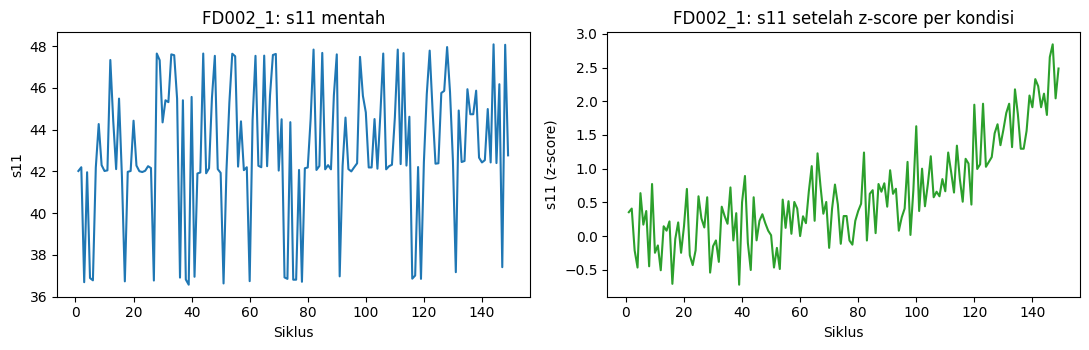

In [72]:
sensor_aktif = schema.SENSOR_AKTIF

norm_stats = {}
for cond in range(6):
    norm_stats[str(cond)] = {}
    df_cond = df_A[df_A['kondisi'] == cond]
    for s in sensor_aktif:
        norm_stats[str(cond)][s] = {
            "mean": float(df_cond[s].mean()),
            "std": float(df_cond[s].std()),
        }

print("Jumlah kondisi:", len(norm_stats))                                  # 6
print("Sensor per kondisi:", len(norm_stats['0']))                          # 14
print("Contoh kondisi 0, s11:", norm_stats['0']['s11'])

std_semua = [norm_stats[c][s]['std'] for c in norm_stats for s in sensor_aktif]
print("Std terkecil:", round(min(std_semua), 4))                            # sekitar 0.0551, harus > 0

with open('/content/models/v1/norm_stats.json', 'w') as f:
    json.dump(norm_stats, f, indent=2)

with open('/content/models/v1/norm_stats.json') as f:
    norm_cek = json.load(f)

print("Isi sama setelah dimuat ulang?", norm_cek == norm_stats)           # True
print(sorted(os.listdir('/content/models/v1')))                            # ['kmeans_cond.joblib', 'norm_stats.json']

isi_conditions = r'''import json
import numpy as np

def load_norm_stats(filepath='models/v1/norm_stats.json'):
    with open(filepath, 'r') as f:
        return json.load(f)

def assign_kondisi(df, kmeans_cond):
    """Tentukan kondisi operasi (0-5) tiap baris dari set1, set2, set3."""
    df['kondisi'] = kmeans_cond.predict(df[['set1', 'set2', 'set3']])
    return df

def apply_normalization(df, norm_stats, sensor_aktif):
    """Z-score per kondisi per sensor. Hasil: kolom {sensor}_norm."""
    for cond in range(6):
        mask = df['kondisi'] == cond
        for s in sensor_aktif:
            mean_val = norm_stats[str(cond)][s]['mean']
            std_val = norm_stats[str(cond)][s]['std']
            df.loc[mask, f'{s}_norm'] = (df.loc[mask, s] - mean_val) / std_val
    return df
'''
with open('/content/engine/conditions.py', 'w') as f:
    f.write(isi_conditions)

print(sorted(os.listdir('/content/engine')))   # ['__init__.py', 'conditions.py', 'data.py', 'schema.py', ...]

import importlib
from engine import conditions
importlib.reload(conditions)

norm_stats = conditions.load_norm_stats('/content/models/v1/norm_stats.json')
df_A = conditions.apply_normalization(df_A, norm_stats, sensor_aktif)

kolom_norm = [f'{s}_norm' for s in sensor_aktif]
print("Kolom baru:", len(kolom_norm))                              # 14
print("Missing di kolom norm:", df_A[kolom_norm].isnull().sum().sum())   # 0

cek_mean = df_A.groupby('kondisi')[kolom_norm].mean().abs().max().max()
cek_std = df_A.groupby('kondisi')[kolom_norm].std()

print("Selisih mean terbesar dari 0 :", cek_mean)
print("Std terkecil / terbesar      :", round(float(cek_std.min().min()), 6), "/", round(float(cek_std.max().max()), 6))

unit_contoh = df_A['unit'].iloc[0]
d = df_A[df_A['unit'] == unit_contoh].sort_values('cycle')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(d['cycle'], d['s11'])
ax[0].set_title(f'{unit_contoh}: s11 mentah')
ax[0].set_xlabel('Siklus'); ax[0].set_ylabel('s11')

ax[1].plot(d['cycle'], d['s11_norm'], color='tab:green')
ax[1].set_title(f'{unit_contoh}: s11 setelah z-score per kondisi')
ax[1].set_xlabel('Siklus'); ax[1].set_ylabel('s11 (z-score)')

plt.tight_layout()
plt.show()

# Membuat Tahap Kesehatan

In [73]:
isi_health = r'''import joblib

NAMA_TAHAP = ['sehat', 'menurun', 'kritis']

def hitung_rolling_mean(df, sensor_aktif, window=10):
    """Rata-rata window siklus terakhir dari sensor ternormalisasi, per mesin.
    Untuk siklus awal (< window) memakai siklus yang tersedia."""
    df = df.sort_values(['unit', 'cycle']).reset_index(drop=True)
    kolom_mean = []
    for s in sensor_aktif:
        nama = f'{s}_mean{window}'
        df[nama] = df.groupby('unit')[f'{s}_norm'].transform(
            lambda x: x.rolling(window=window, min_periods=1).mean())
        kolom_mean.append(nama)
    return df, kolom_mean

def prediksi_tahap_kesehatan(df, kolom_mean, model):
    """model boleh objek KMeans atau jalur file .joblib.
    Cluster 0/1/2 sudah diurutkan: 0 = sehat, 1 = menurun, 2 = kritis."""
    if isinstance(model, str):
        model = joblib.load(model)
    df['cluster_kesehatan'] = model.predict(df[kolom_mean])
    df['tahap'] = df['cluster_kesehatan'].map(dict(enumerate(NAMA_TAHAP)))
    return df
'''
with open('/content/engine/health.py', 'w') as f:
    f.write(isi_health)
print("health.py dibuat")

health.py dibuat


In [74]:
from engine import health
importlib.reload(health)

df_A, kolom_mean10 = health.hitung_rolling_mean(df_A, sensor_aktif, window=10)

print("Jumlah fitur:", len(kolom_mean10))                              # 14
print("Contoh nama :", kolom_mean10[:3])                               # ['s2_mean10', 's3_mean10', 's4_mean10']
print("Missing     :", df_A[kolom_mean10].isnull().sum().sum())        # 0

# uji manual pada satu mesin
d = df_A[df_A['unit'] == 'FD002_1']
print(np.isclose(d['s11_mean10'].iloc[0],  d['s11_norm'].iloc[0]))               # True
print(np.isclose(d['s11_mean10'].iloc[9],  d['s11_norm'].iloc[:10].mean()))      # True
print(np.isclose(d['s11_mean10'].iloc[20], d['s11_norm'].iloc[11:21].mean()))    # True

Jumlah fitur: 14
Contoh nama : ['s2_mean10', 's3_mean10', 's4_mean10']
Missing     : 0
True
True
True


In [75]:
kmeans_health = KMeans(n_clusters=3, n_init=10, random_state=42)
df_A['cluster_kesehatan'] = kmeans_health.fit_predict(df_A[kolom_mean10])

print(df_A['cluster_kesehatan'].value_counts().sort_index())
print(df_A.groupby('cluster_kesehatan')['cycle'].mean().round(1))

cluster_kesehatan
0    43097
1    21276
2     3918
Name: count, dtype: int64
cluster_kesehatan
0     87.7
1    164.8
2    268.9
Name: cycle, dtype: float64


In [76]:
rata_siklus = df_A.groupby('cluster_kesehatan')['cycle'].mean().sort_values()
urutan_lama = rata_siklus.index.tolist()
print("Urutan cluster lama (sehat -> kritis):", urutan_lama)

# susun ulang centroid: 0 = sehat, 1 = menurun, 2 = kritis
kmeans_health.cluster_centers_ = kmeans_health.cluster_centers_[urutan_lama]

df_A = health.prediksi_tahap_kesehatan(df_A, kolom_mean10, kmeans_health)

print(df_A.groupby('cluster_kesehatan')['cycle'].mean().round(1))   # naik: sekitar 88 -> 165 -> 269
print(df_A['tahap'].value_counts())

Urutan cluster lama (sehat -> kritis): [0, 1, 2]
cluster_kesehatan
0     87.7
1    164.8
2    268.9
Name: cycle, dtype: float64
tahap
sehat      43097
menurun    21276
kritis      3918
Name: count, dtype: int64


In [77]:
idx_h = df_A.sample(n=5000, random_state=42).index
sil_kesehatan = float(silhouette_score(df_A.loc[idx_h, kolom_mean10],
                                       df_A.loc[idx_h, 'cluster_kesehatan']))
print("Silhouette tahap kesehatan:", round(sil_kesehatan, 4))      # sekitar 0.39

joblib.dump(kmeans_health, '/content/models/v1/health_kmeans.joblib')

model_cek = joblib.load('/content/models/v1/health_kmeans.joblib')
print("Prediksi sama setelah dimuat ulang?",
      (model_cek.predict(df_A[kolom_mean10]) == df_A['cluster_kesehatan']).all())   # True
print(sorted(os.listdir('/content/models/v1')))   # ['health_kmeans.joblib', 'kmeans_cond.joblib', 'norm_stats.json']

Silhouette tahap kesehatan: 0.39
Prediksi sama setelah dimuat ulang? True
['health_kmeans.joblib', 'kmeans_cond.joblib', 'norm_stats.json']


In [78]:
from engine import conditions

kmeans_cond = joblib.load('/content/models/v1/kmeans_cond.joblib')

df_C = df_all[df_all['unit'].isin(splits['C'])].copy()
df_C = conditions.assign_kondisi(df_C, kmeans_cond)
df_C = conditions.apply_normalization(df_C, norm_stats, sensor_aktif)
df_C, _ = health.hitung_rolling_mean(df_C, sensor_aktif, window=10)
df_C = health.prediksi_tahap_kesehatan(df_C, kolom_mean10, kmeans_health)

print("Mesin C:", df_C['unit'].nunique(), "| baris:", len(df_C))    # 102 mesin
print("Missing norm:", df_C[kolom_norm].isnull().sum().sum())        # 0

Mesin C: 102 | baris: 23623
Missing norm: 0


In [79]:
df_C['umur_maks'] = df_C.groupby('unit')['cycle'].transform('max')
df_C['persen_umur'] = (np.ceil(df_C['cycle'] / df_C['umur_maks'] * 10) * 10).astype(int)

proporsi = pd.crosstab(df_C['persen_umur'], df_C['tahap'], normalize='index')
proporsi = proporsi[['sehat', 'menurun', 'kritis']]
print(proporsi.round(2))
print("Proporsi kritis tidak pernah turun?", proporsi['kritis'].is_monotonic_increasing)

tahap        sehat  menurun  kritis
persen_umur                        
10            0.96     0.04    0.00
20            0.97     0.03    0.00
30            0.95     0.05    0.00
40            0.92     0.08    0.00
50            0.85     0.15    0.00
60            0.79     0.20    0.00
70            0.63     0.33    0.04
80            0.21     0.66    0.13
90            0.04     0.72    0.24
100           0.00     0.71    0.29
Proporsi kritis tidak pernah turun? True


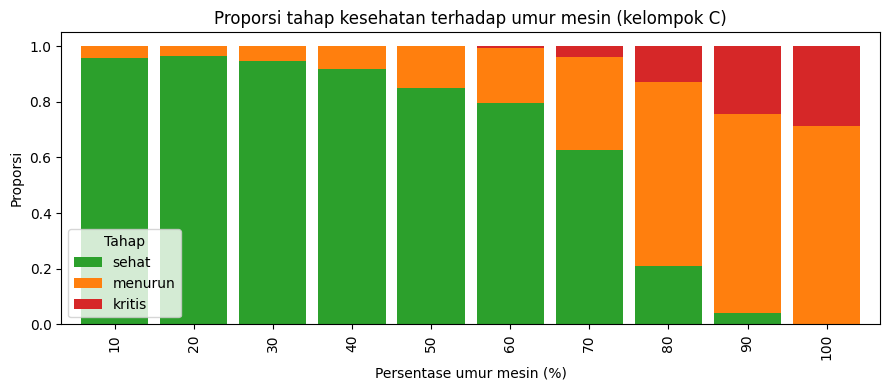

In [80]:
proporsi.plot(kind='bar', stacked=True, figsize=(9, 4),
              color=['tab:green', 'tab:orange', 'tab:red'], width=0.85)
plt.xlabel('Persentase umur mesin (%)')
plt.ylabel('Proporsi')
plt.title('Proporsi tahap kesehatan terhadap umur mesin (kelompok C)')
plt.legend(title='Tahap')
plt.tight_layout()
plt.show()

In [81]:
tujuan = '/content/drive/MyDrive/Praktikum MLN/PrognoSense'
os.makedirs(tujuan, exist_ok=True)
shutil.copytree('/content/models/v1', f'{tujuan}/models_v1', dirs_exist_ok=True)
shutil.copytree('/content/engine', f'{tujuan}/engine', dirs_exist_ok=True)
print("Cadangan tersimpan")

Cadangan tersimpan


# Ekspor Data

In [82]:
def ke_python(o):
    """JSON tidak bisa menyimpan tipe angka NumPy; ubah ke angka Python biasa."""
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    raise TypeError(f"Tipe {type(o)} tidak bisa disimpan ke JSON")

In [83]:
centroid_list = np.round(kmeans_final.cluster_centers_, 4).tolist()

pemilihan_k = [
    {"k": int(k), "wcss": float(w), "silhouette": float(s)}
    for k, w, s in zip(k_range, wcss, silhouettes)
]

sampel_titik = (df_A[['set1', 'set2', 'set3', 'kondisi']]
                .sample(n=2000, random_state=42)
                .to_dict(orient='records'))

print("Centroid     :", len(centroid_list))     # 6
print("Pemilihan K  :", len(pemilihan_k))       # 9 (K = 2 sampai 10)
print("Sampel titik :", len(sampel_titik))      # 2000
print(sampel_titik[0])

Centroid     : 6
Pemilihan K  : 9
Sampel titik : 2000
{'set1': 10.0004, 'set2': 0.2508, 'set3': 100.0, 'kondisi': 3}


In [84]:
unit_contoh = 'FD002_1'
d = df_A[df_A['unit'] == unit_contoh].sort_values('cycle')

sebelum_sesudah = {
    "unit": unit_contoh,
    "sensor": "s11",
    "cycle": d['cycle'].tolist(),
    "mentah": d['s11'].round(4).tolist(),
    "normal": d['s11_norm'].round(4).tolist(),
}

print("Jumlah siklus:", len(sebelum_sesudah['cycle']))
print("Sama dengan umur mesin?", len(d) == int(d['cycle'].max()))    # True
print(sebelum_sesudah['mentah'][:3], sebelum_sesudah['normal'][:3])

Jumlah siklus: 149
Sama dengan umur mesin? True
[42.02, 42.2, 36.69] [0.3534, 0.4071, -0.213]


In [85]:
urutan = ['sehat', 'menurun', 'kritis']

profil = (df_A.groupby('tahap')[kolom_mean10].mean()
          .loc[urutan].round(4).reset_index()
          .to_dict(orient='records'))

per_umur = [
    {"persen_umur": int(p),
     "sehat": round(float(r['sehat']), 2),
     "menurun": round(float(r['menurun']), 2),
     "kritis": round(float(r['kritis']), 2)}
    for p, r in proporsi.iterrows()
]

kesehatan = {
    "k": 3,
    "urutan": urutan,
    "silhouette": float(sil_kesehatan),
    "profil": profil,
    "per_umur": per_umur,
}

print("Profil     :", len(profil), "baris,", len(profil[0]), "kunci per baris")   # 3 baris, 15 kunci
print("Per umur   :", len(per_umur), "baris")                                       # 10
print(per_umur[0], per_umur[-1])

Profil     : 3 baris, 15 kunci per baris
Per umur   : 10 baris
{'persen_umur': 10, 'sehat': 0.96, 'menurun': 0.04, 'kritis': 0.0} {'persen_umur': 100, 'sehat': 0.0, 'menurun': 0.71, 'kritis': 0.29}


In [86]:
kondisi_json = {
    "k": 6,
    "centroid": centroid_list,
    "pemilihan_k": pemilihan_k,
    "sampel_titik": sampel_titik,
    "sebelum_sesudah": sebelum_sesudah,
    "silhouette_kondisi": float(sil_kondisi),
    "kesehatan": kesehatan,
}

with open('/content/data/hasil/kondisi.json', 'w') as f:
    json.dump(kondisi_json, f, indent=2, default=ke_python)

ukuran = os.path.getsize('/content/data/hasil/kondisi.json') / 1024
print(f"kondisi.json tersimpan ({ukuran:.0f} KB)")

kondisi.json tersimpan (198 KB)


In [87]:
with open('/content/data/hasil/kondisi.json') as f:
    kj = json.load(f)

wajib = {"k", "centroid", "pemilihan_k", "sampel_titik", "sebelum_sesudah", "kesehatan"}
print("Kunci kontrak lengkap?", wajib <= set(kj.keys()))                              # True
print("k:", kj['k'], "| centroid:", len(kj['centroid']), "x", len(kj['centroid'][0]))   # 6 | 6 x 3
print("pemilihan_k:", [x['k'] for x in kj['pemilihan_k']])                             # [2, ..., 10]
print("sampel_titik:", len(kj['sampel_titik']),
      "| kondisi unik:", sorted({x['kondisi'] for x in kj['sampel_titik']}))           # 2000 | [0..5]
print("sebelum_sesudah panjang sama?",
      len(kj['sebelum_sesudah']['cycle']) == len(kj['sebelum_sesudah']['mentah']) == len(kj['sebelum_sesudah']['normal']))
print("kesehatan:", kj['kesehatan']['k'], kj['kesehatan']['urutan'], kj['kesehatan']['silhouette'])
print("per_umur persen:", [x['persen_umur'] for x in kj['kesehatan']['per_umur']])     # 10, 20, ..., 100
print("Jumlah tiap baris per_umur ~1?",
      all(abs(x['sehat'] + x['menurun'] + x['kritis'] - 1) <= 0.02 for x in kj['kesehatan']['per_umur']))
print("silhouette_kondisi:", round(kj['silhouette_kondisi'], 4))                       # 0.9997

Kunci kontrak lengkap? True
k: 6 | centroid: 6 x 3
pemilihan_k: [2, 3, 4, 5, 6, 7, 8, 9, 10]
sampel_titik: 2000 | kondisi unik: [0, 1, 2, 3, 4, 5]
sebelum_sesudah panjang sama? True
kesehatan: 3 ['sehat', 'menurun', 'kritis'] 0.39000593776431786
per_umur persen: [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
Jumlah tiap baris per_umur ~1? True
silhouette_kondisi: 0.9997


In [88]:
tujuan = '/content/drive/MyDrive/Praktikum MLN/PrognoSense'
os.makedirs(tujuan, exist_ok=True)
shutil.copytree('/content/data/hasil', f'{tujuan}/hasil', dirs_exist_ok=True)
shutil.copytree('/content/models/v1', f'{tujuan}/models_v1', dirs_exist_ok=True)
shutil.copytree('/content/engine', f'{tujuan}/engine', dirs_exist_ok=True)
shutil.copy('/content/data/splits.json', f'{tujuan}/splits.json')
print(sorted(os.listdir(tujuan)))

['engine', 'hasil', 'models_v1', 'splits.json']


# Memindahkan Fungsi Split ke engine\data.py

In [89]:
tambahan = r'''
import numpy as np

def get_unit_ids(filepath, prefix):
    df = pd.read_csv(filepath, sep=r'\s+', header=None)
    return [f"{prefix}_{int(u)}" for u in df[0].unique()]

def split_60_20_20(unit_list, seed=42):
    np.random.seed(seed)
    shuffled = np.random.permutation(unit_list)
    n = len(shuffled)
    idx_a = int(0.6 * n)
    idx_b = int(0.8 * n)
    return {
        'A': shuffled[:idx_a].tolist(),
        'B': shuffled[idx_a:idx_b].tolist(),
        'C': shuffled[idx_b:].tolist(),
    }
'''
with open('/content/engine/data.py', 'a') as f:
    f.write(tambahan)
print("data.py diperbarui")

data.py diperbarui


Uji apakah hasilnya identik dengan split.json sebelumnya

In [90]:
importlib.reload(data)

s002 = data.split_60_20_20(data.get_unit_ids('/content/data/raw/train_FD002.txt', 'FD002'), seed=42)
s004 = data.split_60_20_20(data.get_unit_ids('/content/data/raw/train_FD004.txt', 'FD004'), seed=42)

ulang = {k: s002[k] + s004[k] for k in ['A', 'B', 'C']}
asli = json.load(open('/content/data/splits.json'))

print("Hasil dari engine identik dengan splits.json?", all(ulang[k] == asli[k] for k in 'ABC'))   # True

Hasil dari engine identik dengan splits.json? True


In [91]:
import platform, sklearn, joblib
print("python      :", platform.python_version())
print("scikit-learn:", sklearn.__version__)
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("joblib      :", joblib.__version__)

python      : 3.13.16
scikit-learn: 1.6.1
numpy       : 2.1.3
pandas      : 2.2.3
joblib      : 1.6.0
